# CLIP — uczenie reprezentacji wizyjno-językowejMultimodalny model łączący obrazy i ich opisy we wspólnej przestrzeni reprezentacji, trenowany kontrastywnie na Flickr30k. Koder tekstu: DistilBERT. Koder obrazu: ResNet50 (timm). Zastosowania: wyszukiwanie obrazów podobnych i wyszukiwanie obrazów zapytaniem tekstowym.

In [ ]:
!pip install -q datasets
!pip install -q timm
!pip install -q torchmetrics
!pip install -q wandb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 19.0 MB/s eta 0:00:00


In [ ]:
from tqdm import tqdm
from PIL import Image
from typing import List, Tuple, Dict, Optional, Any
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
import torchmetrics
import timm

In [ ]:
@dataclass
class Config:
  image_size = 224              # Rozmiar obrazu w pikselach
  projection_dim = 256          # Rozmiar wektorowej reprezentacji (osadzenia)

  # Model językowy do ekstrakcji reprezentacji językowej
  text_model = "distilbert-base-uncased"
  max_tokens = 24               # Maksymalna długość podpisu po tokenizacji

  temperature = 0.05            # Parametr temperatury w funkcji softmax

  # Parametry data loadera
  batch_size = 64
  num_workers = 1

  # Parametry treningu modelu
  num_epochs = 3

  # Wartości stopy uczenia
  image_encoder_lr = 1e-4
  text_encoder_lr = 1e-5
  projection_head_lr = 1e-3
  weight_decay = 1e-4

## Zbiór danych — Flickr30k31 tys. obrazów, każdy z pięcioma niezależnymi podpisami.

In [ ]:
def load_flickr(version: str = "flickr8k") -> Dataset:
  if version == "flickr8k":
    dataset = load_dataset("jxie/flickr8k", cache_dir="./huggingface_data")
  elif version == "flickr30k":
    dataset = load_dataset("umaru97/flickr30k_train_val_test", cache_dir="./huggingface_data")
  else:
    raise NotImplemented(f"Unknown dataset version: {version}")
  return dataset

In [ ]:
flickr_dataset = load_flickr(version="flickr30k")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/871 [00:00<?, ?B/s]

data/train-00000-of-00008-d81a45c0948915(…):   0%|          | 0.00/482M [00:00<?, ?B/s]

data/train-00001-of-00008-5f94761d8704b4(…):   0%|          | 0.00/493M [00:00<?, ?B/s]

data/train-00002-of-00008-d5b746892141fe(…):   0%|          | 0.00/493M [00:00<?, ?B/s]

data/train-00003-of-00008-e656a369da8ee2(…):   0%|          | 0.00/490M [00:00<?, ?B/s]

... (5 outputs left out)

data/test-00000-of-00001-f4c5570f14a435e(…):   0%|          | 0.00/141M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

In [ ]:
print(flickr_dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
        num_rows: 29000
    })
    val: Dataset({
        features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
        num_rows: 1014
    })
    test: Dataset({
        features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
        num_rows: 1000
    })
})


In rural outdoors, blond woman sits on roof of yellow BMW vehicle, two people inside.
Two people drive a Jeep while a lady sits on the top of it.
A girl wearing camouflage pants sits on top of a Hummer.
A four wheel drive vehicle is driving on a dirt track.
Girl on roof of jeep being driven down road


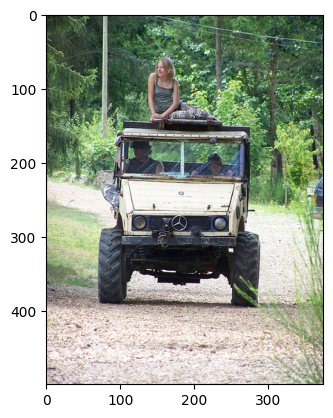

In [ ]:
import random
import matplotlib.pyplot as plt

data_item = random.choice(flickr_dataset['test'])
plt.imshow(data_item['image'])
for caption in data_item['caption']:
    print(f"{caption}")


## Dane tekstoweTokenizator DistilBERT. Dodaje `[CLS]` na początku sekwencji — reprezentacja tego tokenu posłuży jako wektor całego zdania.

In [ ]:
from transformers import DistilBertModel, DistilBertConfig, DistilBertTokenizerFast

In [ ]:
tokenizer = DistilBertTokenizerFast.from_pretrained(Config.text_model)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

In [ ]:
captions = ['Two boys', 'Small cuckoo', 'xewrfjjasderda']

for caption in captions:
  print(f'Tekst: {caption}')
  tokens = tokenizer(caption, add_special_tokens=True, padding='max_length',
                     truncation=True, max_length=Config.max_tokens)
  print(f'Wynik tokenizacji: {tokens}')
  decoded_txt = tokenizer.decode(tokens['input_ids'])
  print(f'Zdekodowane tokeny: {decoded_txt}')
  print()

Tekst: Two boys
Wynik tokenizacji: {'input_ids': [101, 2048, 3337, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
Zdekodowane tokeny: [CLS] two boys [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Tekst: Small cuckoo
Wynik tokenizacji: {'input_ids': [101, 2235, 29010, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
Zdekodowane tokeny: [CLS] small cuckoo [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]

Tekst: xewrfjjasderda
Wynik tokenizacji: {'input_ids': [101, 1060, 7974, 12881, 3501, 17386, 4063, 2850, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 

## Dane wizyjneW trybie treningowym augmentacja, w walidacyjnym wyłącznie skalowanie i normalizacja statystykami ImageNetu.

In [ ]:
from torchvision.transforms import v2

def get_image_transforms(mode: str = "train"):
  if mode == "train":
    transforms = v2.Compose([
        v2.ToImage(),                         # Convert a tensor, ndarray, or PIL Image to tv_tensors.Image
        v2.ToDtype(torch.uint8, scale=True),  # Optional, most input are already uint8 at this point
        v2.RandomResizedCrop(size=(Config.image_size, Config.image_size), antialias=True),
        v2.RandomHorizontalFlip(p=0.5),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
  else:
    transforms = v2.Compose([
        v2.ToImage(),                         # Convert a tensor, ndarray, or PIL Image to tv_tensors.Image
        v2.ToDtype(torch.uint8, scale=True),  # Optional, most input are already uint8 at this point
        v2.Resize(size=(Config.image_size, Config.image_size), antialias=True),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
  return transforms


In [ ]:
image = flickr_dataset['train'][0]['image']
transforms = get_image_transforms('train')
x = transforms(image)
print(type(x))
print(x.shape)

<class 'torchvision.tv_tensors._image.Image'>
torch.Size([3, 224, 224])


In [ ]:
class CLIPDataset(Dataset):
  def __init__(self, dataset: Dataset, tokenizer, image_transforms):
    # dataset: Flickr dataset
    self.dataset = dataset
    self.tokenizer = tokenizer
    self.image_transforms = image_transforms

    # Tokenizacja podpisów
    self.raw_captions = []
    self.tokenized_captions = []
    for data_item in tqdm(dataset, desc="Tokenizacja tekstu..."):
      self.raw_captions.append(data_item['caption'])
      temp = tokenizer(data_item['caption'], add_special_tokens=True, padding='max_length',
                       truncation=True, max_length=Config.max_tokens, return_tensors='pt')
      self.tokenized_captions.append(temp)

  def __getitem__(self, idx) -> Dict[str, Any]:
    image = self.dataset[idx]['image']

    # Zastosuj transformacje, zamień na tensor i znormalizuj
    image = self.image_transforms(image)

    # Wybierz losowo jeden podpis
    k = random.randrange(len(self.tokenized_captions[idx]))
    input_ids = self.tokenized_captions[idx]['input_ids'][k]
    attention_mask = self.tokenized_captions[idx]['attention_mask'][k]
    data_item = {
        'image': image,
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'caption': self.raw_captions[idx][k]
        }
    return data_item

  def __len__(self) -> int:
    return len(self.dataset)

In [ ]:
training_dataset = CLIPDataset(flickr_dataset['train'], tokenizer, get_image_transforms(mode="train"))
val_dataset = CLIPDataset(flickr_dataset['val'], tokenizer, get_image_transforms(mode="val"))

Tokenizacja tekstu...: 100%|██████████| 1014/1014 [00:03<00:00, 283.22it/s]


In [ ]:
for i in range(3):
  x = random.choice(training_dataset)
  print(f"{x['caption']=}")
  print(f"{x['input_ids']=}")
  print(f"{x['attention_mask']=}")
  print(f"{x['image'].shape=}")
  print()

x['caption']='A sleeping baby is wearing a shirt with red trucks on it while being held by a woman.'
x['input_ids']=tensor([ 101, 1037, 5777, 3336, 2003, 4147, 1037, 3797, 2007, 2417, 9322, 2006,
        2009, 2096, 2108, 2218, 2011, 1037, 2450, 1012,  102,    0,    0,    0])
x['attention_mask']=tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0])
x['image'].shape=torch.Size([3, 224, 224])

x['caption']='Three people wearing dark costumes and makeup pose for a picture.'
x['input_ids']=tensor([  101,  2093,  2111,  4147,  2601, 12703,  1998,  5789, 13382,  2005,
         1037,  3861,  1012,   102,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0])
x['attention_mask']=tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
x['image'].shape=torch.Size([3, 224, 224])

x['caption']='Group of African children sitting in the dirt writing on stone tablets.'
x['input_ids']=tensor([  101,  2177,  1997,  3060,  2336,

## Architektura

### Głowica projekcyjnaRzutuje reprezentacje obu modalności do wspólnej przestrzeni o jednakowym wymiarze — warstwa liniowa, GELU, druga warstwa liniowa, dropout i połączenie residualne z LayerNorm.

In [ ]:
class ProjectionHead(nn.Module):
  def __init__(self, embedding_dim: int, projection_dim: int):
    super().__init__()
    self.projection_dim = projection_dim
    self.projection = nn.Linear(in_features=embedding_dim, out_features=projection_dim, bias=False)

  def forward(self, x: Tensor) -> Tensor:
    y = self.projection(x)
    z = F.normalize(y, p=2, dim=1)
    return z

In [ ]:
d_in = 128
d_out = 64
batch_size = 32
proj_head = ProjectionHead(d_in, d_out)
n_params = sum([p.numel() for p in proj_head.parameters()])
assert len(list(proj_head.parameters())) == 1, f"Głowica projekcyjna powinna zawierać tylko pojedyczą warstwę liniową"
assert n_params == d_in * d_out, f"Głowica projekcyjna powinna zawierać tylko pojedynczą warstwę liniową z parametrem bias=False"

assert isinstance(proj_head, nn.Module)
x = torch.rand((batch_size, d_in))
print(f"{x.shape=}")
z = proj_head(x)
print(f"{z.shape=}")

assert z.shape == (batch_size, d_out), f"Nieprawidłowy rozmiar tensora z: {z}"
assert z.norm(dim=1).isclose(torch.tensor(1.)).all(), f"Znormalizuj reprezentację wejściową: {z.norm(dim=1)}"

x.shape=torch.Size([32, 128])
z.shape=torch.Size([32, 64])


### Koder tekstu — DistilBERTReprezentacją sekwencji jest wektor tokenu `[CLS]`.

In [ ]:
class TextEncoder(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    self.backbone = DistilBertModel.from_pretrained(Config.text_model)
    self.embedding_dim = self.backbone.config.dim
    # Jak reprezentację całej sekwencji brana jest reprezentacja tokenu [CLS] na pozycji 0
    self.CLS_token_idx = 0
    self.projection = ProjectionHead(embedding_dim=self.embedding_dim, projection_dim=Config.projection_dim)

  def forward(self, input_ids: Tensor, attention_mask: Tensor) -> Tensor:
    x = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
    last_hidden_state = x.last_hidden_state
    # last_hidden_state is (batch_size, sequence_length, embedding_dim) tensor
    x = last_hidden_state[:, self.CLS_token_idx, :]
    # x is (batch_size, embedding_dim) tensor
    x = self.projection(x)
    # x is (batch_size, projection_dim) tensor
    return x

### Koder obrazu — ResNet50Architektura z `timm`, bez głowicy klasyfikacyjnej.

In [ ]:
class ImageEncoder(nn.Module):
  def __init__(self) -> None:
    super().__init__()
    # Create the network without the last classification layer (num_classes=0)
    self.backbone = timm.create_model('resnet50', pretrained=True,
                                      num_classes=0)
    self.embedding_dim = self.backbone.feature_info[-1]['num_chs']
    self.projection = ProjectionHead(embedding_dim=self.embedding_dim, projection_dim=Config.projection_dim)

  def forward(self, x: Tensor) -> Tensor:
    x = self.backbone(x)
    # x is (batch_size, embedding_dim) tensor
    x = self.projection(x)
    # x is (batch_size, projection_dim) tensor

    return x


In [ ]:
img_encoder = ImageEncoder()
batch_size = 10
x = torch.rand((batch_size, 3, Config.image_size, Config.image_size))
print(x.shape)
y = img_encoder(x)
print(y.shape)

assert y.ndim == 2
assert y.shape[0] == batch_size
assert y.shape[1] == Config.projection_dim

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

torch.Size([10, 3, 224, 224])
torch.Size([10, 256])


### Model CLIPWsad par (obraz, podpis) przechodzi przez oba kodery i obie głowice projekcyjne, dając dwie macierze reprezentacji o tym samym kształcie.

In [ ]:
class CLIPModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.text_encoder = TextEncoder()
    self.image_encoder = ImageEncoder()

  def forward(self, batch):
    text_embeddings = self.text_encoder(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'])
    image_embeddings = self.image_encoder(batch["image"])
    return text_embeddings, image_embeddings

  def print_info(self):
    print(f"Text embedding dimensionality: {self.text_encoder.embedding_dim}   projected: {self.text_encoder.projection.projection_dim}")
    print(f"Image embedding dimensionality: {self.image_encoder.embedding_dim}   projected: {self.image_encoder.projection.projection_dim}")
    nt, na = count_parameters(self.text_encoder)
    print(f"Text encoder parameters (trainable/all): {nt} / {na}")
    nt, na = count_parameters(self.image_encoder)
    print(f"Image encoder parameters (trainable/all): {nt} / {na}")
    nt, na = count_parameters(self)
    print(f"All parameters (trainable/all): {nt} / {na}")


### Kontrastywna funkcja stratyZ temperaturą: pary z tego samego przykładu mają być bliżej siebie niż wszystkie pozostałe kombinacje w batchu — negatywne przykłady biorą się z samego wsadu.

In [ ]:
def CLIP_loss(text_embeddings: Tensor, image_embeddings: Tensor) -> Tuple[Tensor, float, float]:
    assert text_embeddings.shape == image_embeddings.shape
    assert text_embeddings.device == image_embeddings.device

    n = len(text_embeddings)        # Batch size

    # Create labels tensor = tensor([0, 1,..., n-1])
    labels = torch.arange(n).to(text_embeddings.device)

    logits = (text_embeddings @ image_embeddings.T) / Config.temperature
    img_acc, cap_acc = calc_metrics(logits)

    # Calculate cross entropy losses along axis 0 and 1
    loss_i = F.cross_entropy(logits.transpose(0, 1), labels, reduction="mean")
    loss_t = F.cross_entropy(logits, labels, reduction="mean")

    # Calculate the final loss
    loss = (loss_i + loss_t) / 2

    return loss, img_acc, cap_acc

@torch.no_grad
def calc_metrics(logits: torch.Tensor) -> Tuple[float, float]:
    y = torch.arange(len(logits)).to(logits)
    img2cap_match_idx = logits.argmax(dim=1)
    cap2img_match_idx = logits.argmax(dim=0)

    img_acc = (img2cap_match_idx == y).float().mean().item()
    cap_acc = (cap2img_match_idx == y).float().mean().item()

    return img_acc, cap_acc

## TreningOsobne stopy uczenia dla każdej podsieci; metryki trafności osobno dla obrazów i tekstów.

In [ ]:
dataloader = {
    'train': DataLoader(training_dataset, batch_size=Config.batch_size, num_workers=Config.num_workers, shuffle=True),
    'val': DataLoader(val_dataset, batch_size=Config.batch_size, num_workers=Config.num_workers)
}


In [ ]:
clip_model = CLIPModel()
clip_model.print_info()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clip_model.to(device)

params = [
  {"params": clip_model.text_encoder.backbone.parameters(), "lr": Config.text_encoder_lr},
  {"params": clip_model.image_encoder.backbone.parameters(), "lr": Config.image_encoder_lr},
  {"params": clip_model.text_encoder.projection.parameters(), "lr": Config.projection_head_lr, "weight_decay": Config.weight_decay},
  {"params": clip_model.image_encoder.projection.parameters(), "lr": Config.projection_head_lr, "weight_decay": Config.weight_decay},
]
optimizer = torch.optim.AdamW(params, weight_decay=0.)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Text embedding dimensionality: 768   projected: 256
Image embedding dimensionality: 2048   projected: 256
Text encoder parameters (trainable/all): 66559488 / 66559488
Image encoder parameters (trainable/all): 24032320 / 24032320
All parameters (trainable/all): 90591808 / 90591808


In [ ]:
from tqdm import tqdm

# Per-batch metrics
loss_metric = torchmetrics.aggregation.MeanMetric()
img_acc_metric = torchmetrics.aggregation.MeanMetric()
cap_acc_metric = torchmetrics.aggregation.MeanMetric()

for epoch in range(Config.num_epochs):
  for phase in ['train', 'val']:
    loss_metric.reset()
    img_acc_metric.reset()
    cap_acc_metric.reset()

    if phase == 'train':
      clip_model.train()
    else:
      clip_model.eval()

    for batch in tqdm(dataloader[phase]):
      batch['image'] = batch['image'].to(device)
      batch['input_ids'] = batch['input_ids'].to(device)
      batch['attention_mask'] = batch['attention_mask'].to(device)
      with torch.set_grad_enabled(phase=='train'):
        text_embeddings, image_embeddings = clip_model(batch)
        loss, img_acc, cap_acc = CLIP_loss(text_embeddings, image_embeddings)

      loss_metric.update(loss.item())
      img_acc_metric.update(img_acc)
      cap_acc_metric.update(cap_acc)

      # Backward pass and optimization
      if phase == 'train':

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if phase == 'train':
      print(f"({phase})  epoch: {epoch+1}/{Config.num_epochs}  Loss: {loss_metric.compute():.3f}")
    else:
      print(f"({phase})  epoch: {epoch+1}/{Config.num_epochs}  Loss: {loss_metric.compute():.3f}  img2text acc: {img_acc_metric.compute():.3f}  txt2img acc: {cap_acc_metric.compute():.3f}")


100%|██████████| 454/454 [05:31<00:00,  1.37it/s]


(train)  epoch: 1/3  Loss: 2.109


100%|██████████| 16/16 [00:06<00:00,  2.42it/s]


(val)  epoch: 1/3  Loss: 1.519  img2text acc: 0.554  txt2img acc: 0.549


100%|██████████| 454/454 [06:20<00:00,  1.19it/s]


(train)  epoch: 2/3  Loss: 1.461


... (2 outputs left out)

100%|██████████| 454/454 [08:59<00:00,  1.19s/it]


(train)  epoch: 3/3  Loss: 1.239


100%|██████████| 16/16 [00:14<00:00,  1.14it/s]

(val)  epoch: 3/3  Loss: 1.148  img2text acc: 0.656  txt2img acc: 0.656


In [ ]:
import gc

del batch
del loss
del text_embeddings
del image_embeddings
del optimizer
gc.collect()
torch.cuda.empty_cache()
!nvidia-smi

Mon Jan 19 17:35:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   68C    P0             40W /   70W |    1292MiB /  15360MiB |     64%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Wykorzystanie wytrenowanego modelu

In [ ]:
def make_batch(data_item, device):
  # Convert a data item to one-element batch and move to the device
  data_item['image'] = data_item['image'].unsqueeze(0).to(device)
  data_item['input_ids'] = data_item['input_ids'].unsqueeze(0).to(device)
  data_item['attention_mask'] = data_item['attention_mask'].unsqueeze(0).to(device)
  data_item['caption'] = [data_item['caption']]
  return data_item

### Podobieństwo par obraz–podpisReprezentacje dwóch losowych przykładów i podobieństwo w każdej kombinacji obraz–podpis, zgodny i niezgodny.

In [ ]:
test_dataset = CLIPDataset(flickr_dataset['test'], tokenizer, get_image_transforms(mode="test"))

Tokenizacja tekstu...: 100%|██████████| 1000/1000 [00:09<00:00, 110.00it/s]


In [ ]:
clip_model.eval()

e1 = test_dataset[9]
e2 = test_dataset[140]
b1 = make_batch(e1, device)
b2 = make_batch(e2, device)

# *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
b1_text_emb, b1_img_emb = clip_model(b1)
b2_text_emb, b2_img_emb = clip_model(b2)

sim_1_1 = F.cosine_similarity(b1_img_emb, b1_text_emb)
sim_1_2 = F.cosine_similarity(b1_img_emb, b2_text_emb)

sim_2_2 = F.cosine_similarity(b2_img_emb, b2_text_emb)
sim_2_1 = F.cosine_similarity(b2_img_emb, b1_text_emb)

print(f"Cosine similarity image 1 - text 1: {sim_1_1.item():.4f}")
print(f"Cosine similarity image 1 - text 2: {sim_1_2.item():.4f}")
print("-" * 30)
print(f"Cosine similarity image 2 - text 2: {sim_2_2.item():.4f}")
print(f"Cosine similarity image 2 - text 1: {sim_2_1.item():.4f}")

print(f"Success: {sim_1_1 > sim_1_2 and sim_2_2 > sim_2_1}")
# *** KONIEC KODU DO UZUPEŁNIENIA ***


Cosine similarity image 1 - text 1: 0.4378
Cosine similarity image 1 - text 2: 0.1915
------------------------------
Cosine similarity image 2 - text 2: 0.6889
Cosine similarity image 2 - text 1: -0.0919
Success: tensor([True], device='cuda:0')


Image tensor shape: torch.Size([1, 3, 224, 224])
Image embedding shape: torch.Size([256])


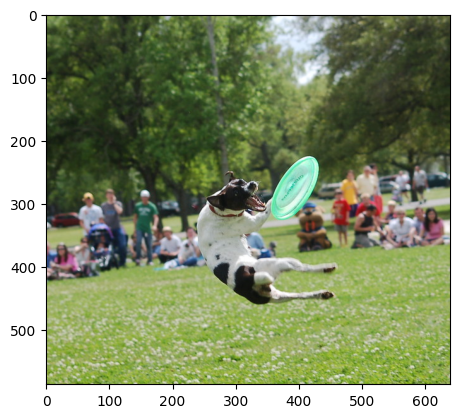

In [ ]:
import requests

url = 'http://farm3.staticflickr.com/2305/2381606562_e87d706d5f_z.jpg'
input_image = Image.open(requests.get(url, stream=True).raw)
plt.imshow(input_image)

transform_to_tensor = get_image_transforms('test')
input_img_tensor = transform_to_tensor(input_image)
input_img_batch = input_img_tensor.unsqueeze(0).to(device)
print(f"Image tensor shape: {input_img_batch.shape}")

clip_model.eval()
input_img_embedding = clip_model.image_encoder(input_img_batch)
input_img_embedding = input_img_embedding.squeeze(0)    # Remove the batch dimension
print(f"Image embedding shape: {input_img_embedding.shape}")

### Reprezentacje całego zbioruWektory wszystkich obrazów zbioru testowego, policzone raz i trzymane w pamięci.

In [ ]:
@torch.no_grad
def compute_image_embeddings(model: CLIPModel, dataset: Dataset) -> Tensor:
  # Compute embeddings for all images in the dataset
  model.eval()
  embeddings = torch.zeros((len(dataset), model.image_encoder.projection.projection_dim), device=device)

  for ndx, data_item in enumerate(tqdm(dataset)):
    batch = make_batch(data_item, device)

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    images = batch["image"]
    image_features = model.image_encoder(images)
    embeddings[ndx] = image_features.squeeze(0)

    # *** KONIEC KODU DO UZUPEŁNIENIA ***

  assert embeddings.shape == (len(dataset), model.image_encoder.projection.projection_dim)
  return embeddings


In [ ]:
image_embeddings = compute_image_embeddings(clip_model, test_dataset)
assert image_embeddings.shape == (len(test_dataset), clip_model.image_encoder.projection.projection_dim)

print()
print(image_embeddings.shape)


100%|██████████| 1000/1000 [00:11<00:00, 87.55it/s]


torch.Size([1000, 256])


### Wyszukiwanie najbliższych sąsiadów

In [ ]:
def find_nn(query_embedding: Tensor, dataset_embeddings: Tensor, k: int) -> Tuple[List[int], List[float]]:
    # Return indices of k embeddings closest to the query embedding
    # query_embedding: tensor (projection_dim, )
    # dataset_embeddings: tensor (dataset_size, projection_dim)

    assert query_embedding.ndim == 1
    assert dataset_embeddings.ndim == 2
    assert query_embedding.shape[0] == dataset_embeddings.shape[1]

    # *** POCZĄTEK KODU DO UZUPEŁNIENIA ***
    # Compute the cosine similarity between the queyr_embedding and embeddings of test set images
    sim = F.cosine_similarity(query_embedding.unsqueeze(0), dataset_embeddings, dim=1)
    # sim is (dataset_size,) tensor
    sim, nn_idx = torch.topk(sim, k)
    # Find indices of k items the most simlar to query_embedding

    # *** KONIEC KODU DO UZUPEŁNIENIA ***

    return nn_idx.tolist(), sim.tolist()


In [ ]:
n = 101
test_img_embedding = image_embeddings[n]

k = 5
nn_idx, sim = find_nn(test_img_embedding, image_embeddings, k=k)
print(nn_idx)
print(sim)

assert len(nn_idx) == k
assert len(sim) == k

assert nn_idx[0] == n, f"Element o indeksie {n} powinien być zwrócony jako pierwszy - jako najbardziej podobny do siebie samego"
assert sim[0] > .9999

assert all([sim[i] - sim[i+1] > 0 for i in range(k-1)]), "Zwrócone podobieństwa muszą być w malejącej kolejności"

[101, 866, 657, 340, 248]
[1.0, 0.9322247505187988, 0.8703311085700989, 0.7198537588119507, 0.6656749248504639]


5 najbliższych sądiadów w przestrzeni reprezentacji: [281, 1, 285, 140, 329]


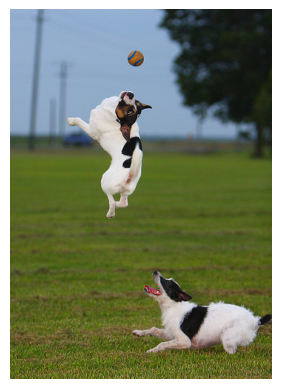

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.755 
['The two dogs, one of which is leaping in the air, are chasing a ball outdoors.', 'One dog leaps to catch a softball while another looks on.', 'Two small dogs pursuing a ball across a grassy field.', 'Two dogs play catch with a ball in a field.', 'Two dogs jump for a ball on a green field.']


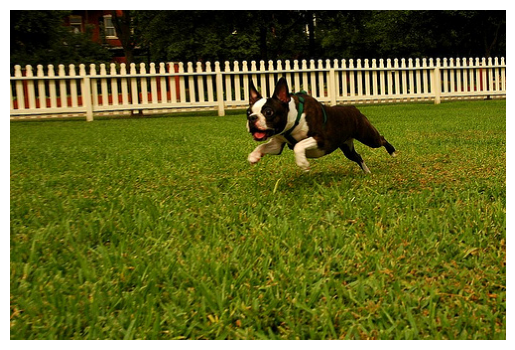

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.667 
['A black and white dog is running in a grassy garden surrounded by a white fence.', 'A Boston Terrier is running on lush green grass in front of a white fence.', 'A black and white dog is running through the grass.', 'A dog runs on the green grass near a wooden fence.', 'A Boston terrier is running in the grass.']


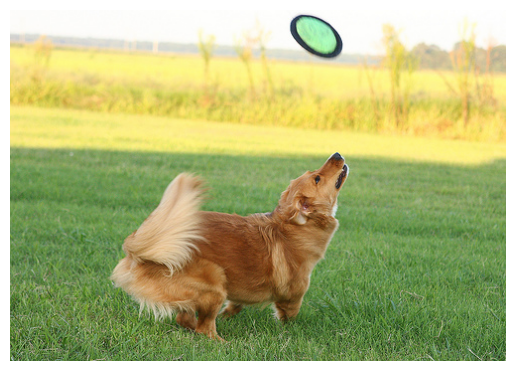

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.663 
['A brown dog waits for the Frisbee to come down before catching it.', 'Dog standing in grass playing with green flying disc', 'A brown dog about to catch a green Frisbee.', 'A dog gets ready to catch a Frisbee.', 'A dog catching a Frisbee.']


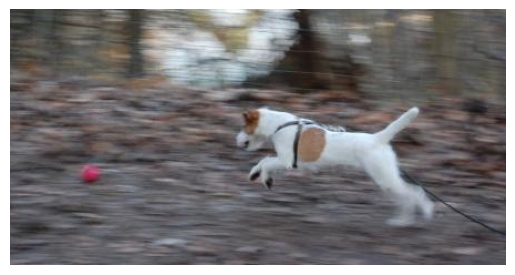

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.637 
['Little white dog wearing a leash jumping after a red ball.', 'A white and brown dog jumps towards a red ball.', 'A small dog on a leash jumps toward a pink ball', 'A fox terrier leaps after a ball.', 'A terrier chasing a red ball.']


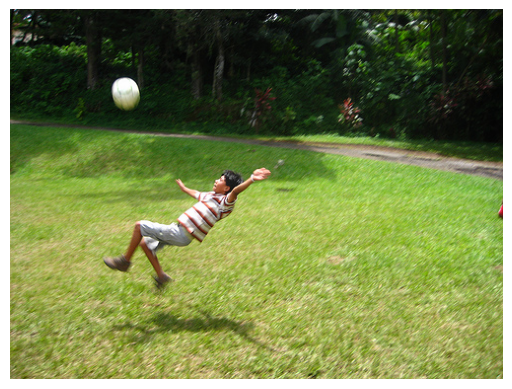

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.626 
['A boy in a stripy shirt is playing with a soccer ball in a grassy park in front of some bushes.', 'Boy leaning backward to kick a soccer ball in midair.', 'A boy leaping in the air towards a soccer ball.', 'A child falling back to kick a soccer ball.', 'A boy in midair trying to kick a soccer ball']


In [ ]:
k = 5
nn_idx, dist = find_nn(input_img_embedding, image_embeddings, k=k)

print(f"{k} najbliższych sądiadów w przestrzeni reprezentacji: {nn_idx}")

for idx, d in zip(nn_idx, dist):
  #item = test_dataset[idx]
  img = test_dataset.dataset[idx]['image']
  plt.imshow(img)
  plt.axis("off")
  plt.show()
  print(f"Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: {d:0.3f} ")
  print(test_dataset.raw_captions[idx])

### Wyszukiwanie obrazów zapytaniem tekstowymZapytanie w języku naturalnym trafia do kodera tekstu, a jego reprezentacja jest porównywana z reprezentacjami obrazów — to jest właśnie ta zdolność, dla której trenuje się CLIP.

In [ ]:
#text_prompt = "a child looking at the sky"
text_prompt = "a man and a red car"

# Encode the text prompt and compute its embedding
# See how the text is tokenized inside the CLIPDataset class
tokenized_prompt = tokenizer(text_prompt, add_special_tokens=True, padding='max_length', truncation=True, max_length=Config.max_tokens, return_tensors='pt')
print(tokenized_prompt)

clip_model.eval()
text_prompt_embedding = clip_model.text_encoder(tokenized_prompt['input_ids'].to(device), tokenized_prompt['attention_mask'].to(device))
text_prompt_embedding = text_prompt_embedding.squeeze(0)   # Remove the batch dimension

print(f"Text embedding shape: {text_prompt_embedding.shape}")


{'input_ids': tensor([[ 101, 1037, 2158, 1998, 1037, 2417, 2482,  102,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}
Text embedding shape: torch.Size([256])


5 nearest neighbours: [514, 241, 515, 258, 589]


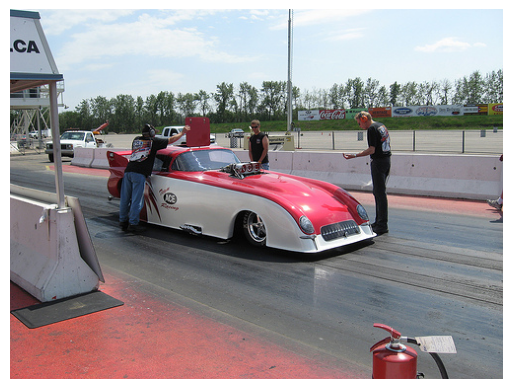

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.719 
['A drag race car being worked on by 3 people on a track', 'Three men are examining a red and white race car.', 'Three men standing around a car on a racetrack.', 'Several men standing around an antique race car', 'Pit crew working on a race car.']


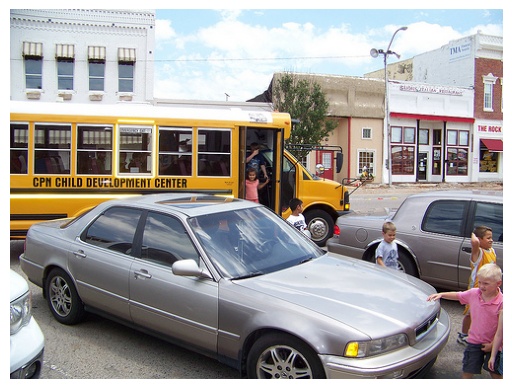

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.579 
['The school bus is unloading children near the parked cars.', 'Small children are getting off a school bus.', 'Parked cars with a school bus behind them.', 'Kids getting off a yellow school bus.', 'The children are getting off the bus.']


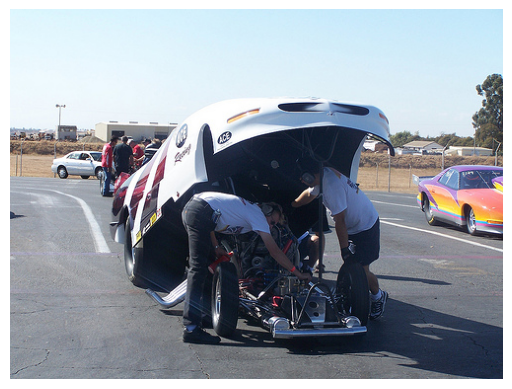

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.542 
["Two men wearing earmuffs inspect a racing car's engine on an asphalt track.", 'Two men work under the hood of a white race car.', 'Two mechanics are fixing a racing white car.', 'Two mechanics working on a drag racing car.', 'Two men under the body of a drag car.']


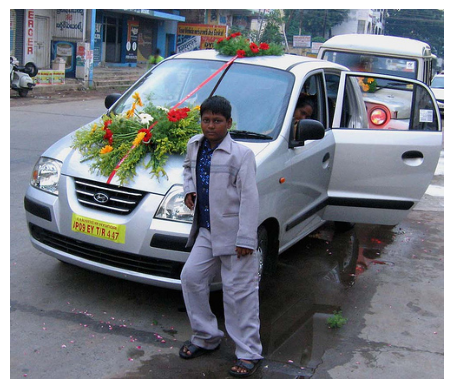

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.541 
['A young boy in a white suit stands in front of a white car with large bunches of flowers tied to the roof and hood.', 'A young boy leans against a car adorned with floral arrangements while the driver looks on.', 'A young dark-skinned fellow poses for a picture in front of a car covered with flowers.', 'A boy is leaning up against a car adorned with flowers.', 'A boy is leaning on a car with flowers on the hood.']


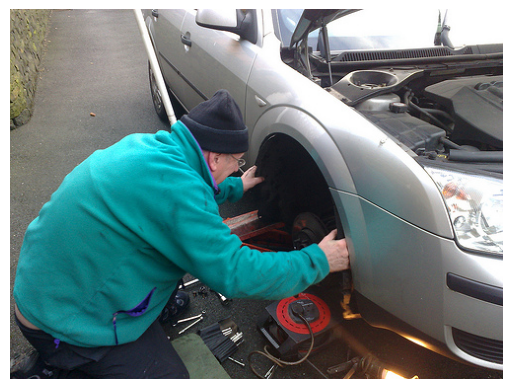

Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: 0.521 
['A man works on his car as he tries to keep warm with his hat and sweatshirt.', 'An elderly man in a light blue coat works on a car on the roadside.', 'Older man in a teal fleece jacket working on a car.', 'A man in a green jacket is working on his tire.', 'A man in a green jacket working on a car.']


In [ ]:
nn_idx, dist = find_nn(text_prompt_embedding, image_embeddings, k=5)

print(f"{k} nearest neighbours: {nn_idx}")

for idx, d in zip(nn_idx, dist):
  #item = test_dataset[idx]
  img = test_dataset.dataset[idx]['image']
  plt.imshow(img)
  plt.axis("off")
  plt.show()
  print(f"Podobieństwo kosinusowe (w przestrzeni reprezentacji) do zapytania: {d:0.3f} ")
  print(test_dataset.raw_captions[idx])